# 2 · A network on top of the search

Notebook 1's tile search finds one motion a tile and moves N and N+2 half of it towards each
other. Can a neural network make it more precise?

Extrapolation's answer was no: every network trained on two frames hedged, and a correction on
top of its search drifted off it from the first epoch (`../frame_gen_extra/summary.md`,
"Motion"). Interpolation is the case where learned methods usually win - both ends of the
motion are known - so it is measured again here, on the method that is already best:

1. **The network.** `models.Refine`: the search, and a small network that sees N, N+2 and the
   search's two reads and corrects them per pixel - a motion correction for each side (so N+1
   need not be half way), a blend mask (so a pixel only one frame shows can come from it), and
   pixels it draws itself, in three combinations. Its last convolution starts at zero, so
   untrained it *is* the search, and every gain is over it.
2. **The loss.** L1 and MSE, and `metrics.log_wmse`, the score itself.
3. **The ceiling.** An oracle that sees N+1 and chooses, per sample or per 8x8 cell, where on
   the motion N+1 lies and which frame to read it from: how much is there to gain, and where.
4. **A rule instead.** `models.Commit`, which reads N alone where the search's two reads
   disagree.

Needs: `00_data_preprocess.ipynb`. Results: `summary.md`, "A network on top".

In [1]:
"""Settings and data."""

import matplotlib.pyplot as plt
import numpy as np
import torch

from helpers import metrics, models, runs, training, webexport
from helpers.training import DATA_DIR, DEVICE

RUN_DIR = training.CHECKPOINT_DIR / "refine_runs"   # each training, resumable
HALO = 8                     # trained and scored at 8, as extrapolation's networks; also scored at 4
BATCH_SIZE = 64
MAX_EPOCHS = 300             # a safety limit; training stops once it has converged
SEED = 0
KINDS = ["page", "desktop", "photo", "video", "cursor"]

def search():
    """Notebook 1's published search."""
    return models.TileSearch(radius=4, scale=2, sharpness=10.0, stride=2, fraction=0.5, still=0.1)

manifest = training.load_manifest()
training.describe(manifest)
train_loader = training.loader(DATA_DIR, manifest, BATCH_SIZE, halo=HALO)

validation = {}
for halo in (HALO, webexport.TILE_HALO):
    inputs, targets = runs.load(DATA_DIR, "val", manifest, halo=halo)
    masks = runs.groups(manifest, "val", inputs, targets, halo)
    for kind in KINDS:
        masks[f"{kind}, changed"] = masks[kind] & masks["changed"]
    validation[halo] = (inputs, targets, masks)
inputs, targets, masks = validation[HALO]
print("val    ", inputs.shape, "->", targets.shape, f"- {masks['changed'].sum()} changed")

device  cuda NVIDIA GeForce RTX 3090
stream  x2 down from a 1280x720 window, 60 fps
run     96 px (64 px + a halo of 16), 8 frames each
stream  every 2th frame received - the inputs are frames N and N+2, the target N+1 between them (2x frame generation)
train  11510 runs from 754 sources


val     (1730, 2, 80, 80, 3) -> (1730, 80, 80, 3) - 868 changed


In [2]:
"""The bar: notebook 1's methods at a halo of 8."""

BASELINES = {
    "hold N": models.Hold(),
    "mean (the mock)": models.Blend(0.5),
    "tile search": models.Interpolate(search()),
    "tile search + pick": models.TilePick(search(), window=15, sharpness=3.0),
}
results = {name: training.evaluate(model, inputs, targets, masks, HALO) for name, model in BASELINES.items()}

def table(results, group="changed"):
    base = results["tile search"][group]["wpsnr"]
    print(f"{'wPSNR, ' + group:<34}{'all':>8}{'unchgd':>8}" + "".join(f"{k:>9}" for k in KINDS) + f"{'SSIM-Y':>9}{'vs search':>11}")
    for name, r in results.items():
        print(f"{name:<34}{r[group]['wpsnr']:8.2f}{r['unchanged']['wpsnr']:8.2f}"
              + "".join(f"{r[f'{k}, changed']['wpsnr']:9.2f}" for k in KINDS)
              + f"{r[group]['ssim']:9.4f}{r[group]['wpsnr'] - base:+11.2f}")

table(results)

wPSNR, changed                         all  unchgd     page  desktop    photo    video   cursor   SSIM-Y  vs search
hold N                               26.89   86.28    25.55    25.64    24.00    39.25    25.19   0.6663     -10.31
mean (the mock)                      28.18   87.16    25.41    27.73    27.11    40.22    26.11   0.6938      -9.02
tile search                          37.20   87.24    36.54    30.10    39.15    41.84    33.14   0.9102      +0.00
tile search + pick                   37.30   87.24    36.66    30.33    39.18    41.91    33.41   0.9124      +0.10


## 1 · The network

`models.Refine(search, parts)`: N, N+2 and the search's two reads (12 channels) into
`TwoScale`'s body - two stride-2 3x3 convolutions of 16 and 32 channels, three 3x3 at a
quarter of the resolution, `DepthToSpace` back up - and out at full resolution:

| parts | what it changes | parameters |
| --- | --- | --- |
| `residual` | adds pixels it draws to the search's result - a picture, as extrapolation's notebook 2 | 36,732 |
| `flow`, `mask` | moves where N and where N+2 are read, each on its own, and mixes the two reads per pixel | 38,468 |
| `flow`, `mask`, `residual` | all of it | 41,072 |

Each starts as the search. Trained at a halo of 8 with Adam - from 1e-4 where it moves reads
(offsets are in pixels: extrapolation's notebook 3 found 1e-3 too large a step), 1e-3 for the
picture alone - halving the rate when the score stalls, keeping the epoch with the best wPSNR
on the changed samples, until it converges. A sample's two frames are swapped in time half the
time: the frame between N and N+2 is the frame between N+2 and N.

**The loss** comes first, because it decided the result before anything else did. Two runs
of the motion network, under MSE and under `log_wmse`:

In [3]:
"""flow + mask under MSE and under the score itself."""

LOSSES = {"mse": lambda a, b: torch.nn.functional.mse_loss(a, b), "l1": metrics.luma_chroma_l1,
          "log_wmse": metrics.log_wmse}
RUNS = {  # name: (parts, learning rate, loss)
    "flow + mask, MSE": (("flow", "mask"), 1e-4, "mse"),
    "flow + mask, L1": (("flow", "mask"), 1e-4, "l1"),
    "flow + mask": (("flow", "mask"), 1e-4, "log_wmse"),
    "residual": (("residual",), 1e-3, "log_wmse"),
    "flow + mask + residual": (("flow", "mask", "residual"), 1e-4, "log_wmse"),
}
networks, histories, bests = {}, {}, {}

def run(name):
    parts, rate, loss = RUNS[name]
    training.seed_everything(SEED)
    networks[name] = models.Refine(search(), parts)
    histories[name], bests[name] = training.train(
        networks[name], train_loader, validation[HALO], HALO, MAX_EPOCHS, learning_rate=rate,
        loss_fn=LOSSES[loss], select=("changed", "wpsnr"), verbose=2,
        checkpoint=RUN_DIR / f"{name.replace(' ', '_').replace('+', 'and').replace(',', '')}_halo{HALO}.pt")

for name in ("flow + mask, MSE", "flow + mask, L1", "flow + mask"):
    run(name)

Training until the model stops improving, at most 300 epochs. Untrained model (repeat): val_changed_wpsnr: 37.1981.
The training is saved to /home/henrik/projects/desktop-streamer-ai/src/frame_gen_intra/checkpoints/refine_runs/flow_and_mask_MSE_halo8.pt after every epoch.
Epoch 1/300


179/179 [==============================] - 12s 65ms/step - loss: 0.0019 - val_changed_ssim_y: 0.9101 - val_changed_wpsnr: 36.1233 - val_unchanged_wpsnr: 57.3991 - learning_rate: 1.0e-04
Epoch 1: val_changed_wpsnr did not improve from 37.1981 (1 of 6 epochs without improvement)
Epoch 2/300


179/179 [==============================] - 5s 27ms/step - loss: 0.0020 - val_changed_ssim_y: 0.9102 - val_changed_wpsnr: 36.4307 - val_unchanged_wpsnr: 60.3162 - learning_rate: 1.0e-04
Epoch 2: val_changed_wpsnr did not improve from 37.1981 (2 of 6 epochs without improvement)
Epoch 3/300


179/179 [==============================] - 4s 21ms/step - loss: 0.0019 - val_changed_ssim_y: 0.9102 - val_changed_wpsnr: 36.3721 - val_unchanged_wpsnr: 59.9665 - learning_rate: 1.0e-04
Epoch 3: val_changed_wpsnr did not improve from 37.1981 (3 of 6 epochs without improvement)
Epoch 4/300


179/179 [==============================] - 3s 18ms/step - loss: 0.0019 - val_changed_ssim_y: 0.9102 - val_changed_wpsnr: 36.3216 - val_unchanged_wpsnr: 59.5936 - learning_rate: 1.0e-04
Epoch 4: val_changed_wpsnr did not improve from 37.1981 (4 of 6 epochs without improvement)
Epoch 5/300


179/179 [==============================] - 3s 17ms/step - loss: 0.0019 - val_changed_ssim_y: 0.9103 - val_changed_wpsnr: 36.3697 - val_unchanged_wpsnr: 60.7585 - learning_rate: 1.0e-04
Epoch 5: val_changed_wpsnr did not improve from 37.1981 (5 of 6 epochs without improvement)
Epoch 6/300


... (138 outputs left out)

179/179 [==============================] - 3s 17ms/step - loss: -4.1493 - val_changed_ssim_y: 0.9108 - val_changed_wpsnr: 37.1522 - val_unchanged_wpsnr: 77.8882 - learning_rate: 1.0e-06
Epoch 45: val_changed_wpsnr did not improve from 37.1981 (3 of 6 epochs without improvement)
Epoch 46/300


179/179 [==============================] - 3s 17ms/step - loss: -4.1475 - val_changed_ssim_y: 0.9108 - val_changed_wpsnr: 37.1529 - val_unchanged_wpsnr: 78.0202 - learning_rate: 1.0e-06
Epoch 46: val_changed_wpsnr did not improve from 37.1981 (4 of 6 epochs without improvement)
Epoch 47/300


179/179 [==============================] - 3s 17ms/step - loss: -4.1448 - val_changed_ssim_y: 0.9108 - val_changed_wpsnr: 37.1530 - val_unchanged_wpsnr: 78.0396 - learning_rate: 1.0e-06
Epoch 47: val_changed_wpsnr did not improve from 37.1981 (5 of 6 epochs without improvement)
Epoch 48/300


179/179 [==============================] - 3s 17ms/step - loss: -4.1366 - val_changed_ssim_y: 0.9108 - val_changed_wpsnr: 37.1527 - val_unchanged_wpsnr: 78.0507 - learning_rate: 1.0e-06
Epoch 48: val_changed_wpsnr did not improve from 37.1981 (6 of 6 epochs without improvement)
Epoch 48: stopping (converged - no improvement in 6 epochs, even at the smallest learning rate)
Restoring model weights from the end of the best epoch: 0 (val_changed_wpsnr: 37.1981, +0.0000 over repeat). Training took 48 epochs, 2.3 min.


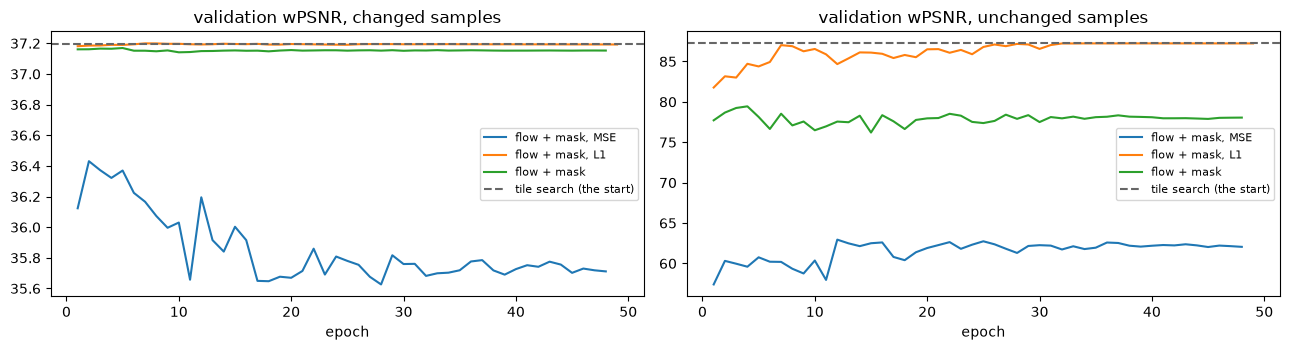

flow + mask, MSE     best epoch   0, 48 epochs; after the first: changed 36.12, unchanged 57.40 dB
flow + mask, L1      best epoch   7, 49 epochs; after the first: changed 37.18, unchanged 81.77 dB
flow + mask          best epoch   0, 48 epochs; after the first: changed 37.16, unchanged 77.71 dB


In [4]:
"""What each loss did to the score, epoch by epoch - the untrained network is the search."""

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for name in ("flow + mask, MSE", "flow + mask, L1", "flow + mask"):
    epochs = range(1, len(histories[name]) + 1)
    axes[0].plot(epochs, [h["scores"]["changed"]["wpsnr"] for h in histories[name]], label=name)
    axes[1].plot(epochs, [h["scores"]["unchanged"]["wpsnr"] for h in histories[name]], label=name)
for ax, group in zip(axes, ("changed", "unchanged")):
    ax.axhline(results["tile search"][group]["wpsnr"], color="0.4", ls="--", label="tile search (the start)")
    ax.set_title(f"validation wPSNR, {group} samples")
    ax.set_xlabel("epoch")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
for name in ("flow + mask, MSE", "flow + mask, L1", "flow + mask"):
    h = histories[name]
    print(f"{name:<20} best epoch {bests[name]['epoch']:3}, {len(h)} epochs; after the first: changed "
          f"{h[0]['scores']['changed']['wpsnr']:.2f}, unchanged {h[0]['scores']['unchanged']['wpsnr']:.2f} dB")

Under MSE the network loses a dB of score on the changed samples from the first epoch, and
30 dB on the still ones (87.2 to 57.4): the loss is a mean over pixels, ruled by the samples
with the largest errors - a menu, an uncovered desktop - where a blur lowers it; the score is a
mean of decibels per sample, ruled by the many with small errors, where the blur costs most.
L1 (81.8 on the still samples after one epoch) and `log_wmse` (77.7) damage much less - and
none of the three ever beats its start: their best epochs are the untrained search, or +0.001
dB (L1). The other two networks, under `log_wmse`:

In [5]:
for name in ("residual", "flow + mask + residual"):
    run(name)

for name in RUNS:
    results[name] = training.evaluate(networks[name], inputs, targets, masks, HALO)
table(results)

Training until the model stops improving, at most 300 epochs. Untrained model (repeat): val_changed_wpsnr: 37.1981.
The training is saved to /home/henrik/projects/desktop-streamer-ai/src/frame_gen_intra/checkpoints/refine_runs/residual_halo8.pt after every epoch.
Epoch 1/300


179/179 [==============================] - 3s 15ms/step - loss: -4.1300 - val_changed_ssim_y: 0.9102 - val_changed_wpsnr: 37.1212 - val_unchanged_wpsnr: 73.0384 - learning_rate: 1.0e-03
Epoch 1: val_changed_wpsnr did not improve from 37.1981 (1 of 6 epochs without improvement)
Epoch 2/300


179/179 [==============================] - 3s 16ms/step - loss: -4.1417 - val_changed_ssim_y: 0.9102 - val_changed_wpsnr: 37.1015 - val_unchanged_wpsnr: 71.2568 - learning_rate: 1.0e-03
Epoch 2: val_changed_wpsnr did not improve from 37.1981 (2 of 6 epochs without improvement)
Epoch 3/300


179/179 [==============================] - 3s 15ms/step - loss: -4.1502 - val_changed_ssim_y: 0.9102 - val_changed_wpsnr: 37.1036 - val_unchanged_wpsnr: 71.3138 - learning_rate: 1.0e-03
Epoch 3: val_changed_wpsnr did not improve from 37.1981 (3 of 6 epochs without improvement)
Epoch 4/300


179/179 [==============================] - 3s 15ms/step - loss: -4.1431 - val_changed_ssim_y: 0.9102 - val_changed_wpsnr: 37.1402 - val_unchanged_wpsnr: 74.3140 - learning_rate: 1.0e-03
Epoch 4: val_changed_wpsnr did not improve from 37.1981 (4 of 6 epochs without improvement)
Epoch 5/300


179/179 [==============================] - 3s 15ms/step - loss: -4.1444 - val_changed_ssim_y: 0.9102 - val_changed_wpsnr: 37.1401 - val_unchanged_wpsnr: 74.1260 - learning_rate: 1.0e-03
Epoch 5: val_changed_wpsnr did not improve from 37.1981 (5 of 6 epochs without improvement)
Epoch 6/300


... (89 outputs left out)

179/179 [==============================] - 3s 17ms/step - loss: -4.1508 - val_changed_ssim_y: 0.9106 - val_changed_wpsnr: 37.0808 - val_unchanged_wpsnr: 75.4157 - learning_rate: 1.0e-06
Epoch 46: val_changed_wpsnr did not improve from 37.1981 (4 of 6 epochs without improvement)
Epoch 47/300


179/179 [==============================] - 3s 17ms/step - loss: -4.1501 - val_changed_ssim_y: 0.9106 - val_changed_wpsnr: 37.0796 - val_unchanged_wpsnr: 75.7965 - learning_rate: 1.0e-06
Epoch 47: val_changed_wpsnr did not improve from 37.1981 (5 of 6 epochs without improvement)
Epoch 48/300


179/179 [==============================] - 3s 16ms/step - loss: -4.1403 - val_changed_ssim_y: 0.9106 - val_changed_wpsnr: 37.0813 - val_unchanged_wpsnr: 75.6569 - learning_rate: 1.0e-06
Epoch 48: val_changed_wpsnr did not improve from 37.1981 (6 of 6 epochs without improvement)
Epoch 48: stopping (converged - no improvement in 6 epochs, even at the smallest learning rate)
Restoring model weights from the end of the best epoch: 0 (val_changed_wpsnr: 37.1981, +0.0000 over repeat). Training took 48 epochs, 2.4 min.


wPSNR, changed                         all  unchgd     page  desktop    photo    video   cursor   SSIM-Y  vs search
hold N                               26.89   86.28    25.55    25.64    24.00    39.25    25.19   0.6663     -10.31
mean (the mock)                      28.18   87.16    25.41    27.73    27.11    40.22    26.11   0.6938      -9.02
tile search                          37.20   87.24    36.54    30.10    39.15    41.84    33.14   0.9102      +0.00
tile search + pick                   37.30   87.24    36.66    30.33    39.18    41.91    33.41   0.9124      +0.10
flow + mask, MSE                     37.20   87.24    36.54    30.10    39.15    41.84    33.14   0.9102      +0.00
flow + mask, L1                      37.20   87.02    36.54    30.11    39.15    41.85    33.14   0.9103      +0.00
flow + mask                          37.20   87.24    36.54    30.10    39.15    41.84    33.14   0.9102      +0.00
residual                             37.20   87.24    36.54    30.10    

In [6]:
"""At the client's halo of 4 - the networks were trained at 8."""

x4, y4, m4 = validation[webexport.TILE_HALO]
for name, model in {**BASELINES, **{name: networks[name] for name in ("flow + mask", "flow + mask + residual")}}.items():
    r = training.evaluate(model, x4, y4, m4, webexport.TILE_HALO)["changed"]
    print(f"{name:<26}{r['wpsnr']:8.2f} dB {r['ssim']:.4f}")

hold N                       26.89 dB 0.6663


mean (the mock)              28.18 dB 0.6938


tile search                  36.86 dB 0.9087


tile search + pick           36.83 dB 0.9117


flow + mask                  36.86 dB 0.9087


flow + mask + residual       36.86 dB 0.9087


## 2 · The ceiling

The network finds nothing. Either there is nothing to find, or two frames do not show it.
An oracle that sees N+1 tells the two apart: it chooses among candidates made from the search's
motion d - N+1 read at a time t between N and N+2 (N at -t·d, N+2 at +(1-t)·d, averaged), or
read from **one side** only (N moved half way, or N+2 moved back half way) - per sample, or per
8x8 cell. Split by how the source was streamed, since the target is a decoded frame of a
60 fps encode whose N+1 the codec predicted from N: with no codec there is no such link.

In [7]:
"""The oracle, on the changed samples."""

changed = np.flatnonzero(masks["changed"])
TIMES = (0.3, 0.4, 0.5, 0.6, 0.7)
made = {}
with torch.no_grad():
    finder = search().to(DEVICE)
    for first in range(0, len(changed), 128):
        index = changed[first:first + 128]
        previous, current = training.to_tensor(inputs[index]).unbind(1)
        motion = 2 * finder(previous, current).expand(-1, -1, *current.shape[-2:])    # N to N+2
        keep = lambda name, picture: made.setdefault(name, []).append(runs.trim(picture, HALO).cpu())
        keep("truth", training.to_tensor(targets[index]))
        for t in TIMES:
            before, after = models.warp(previous, -t * motion), models.warp(current, (1 - t) * motion)
            keep(f"both, t={t}", 0.5 * (before + after))
            if t == 0.5:
                keep("N only", before)
                keep("N+2 only", after)
made = {name: torch.cat(pictures) for name, pictures in made.items()}
truth = made.pop("truth")
WEIGHT = torch.tensor(metrics.WEIGHTS) / sum(metrics.WEIGHTS)

def error_map(picture):
    """Weighted squared error per pixel, (N, H, W)."""
    return ((metrics.rgb_to_yuv(picture) - metrics.rgb_to_yuv(truth)) ** 2 * WEIGHT.view(1, 3, 1, 1)).sum(1)

def db(error):
    return 10 * torch.log10(1 / error.clamp_min(1e-10))

per_sample = {name: db(error_map(picture).mean(dim=(1, 2))) for name, picture in made.items()}

def best_of(names, cell=None):
    """Per sample, the best candidate's dB - or with `cell`, per cell, the best candidate's error."""
    if cell is None:
        return torch.stack([per_sample[name] for name in names], 1).max(1).values
    errors = torch.stack([torch.nn.functional.avg_pool2d(error_map(made[name])[:, None], cell)[:, 0] for name in names], 1)
    return db(errors.min(1).values.mean(dim=(1, 2)))

sides = ["both, t=0.5", "N only", "N+2 only"]
rows = {
    "search (both, t = ½)": per_sample["both, t=0.5"],
    "N only": per_sample["N only"],
    "N+2 only": per_sample["N+2 only"],
    "oracle per sample: t": best_of([f"both, t={t}" for t in TIMES]),
    "oracle per sample: side": best_of(sides),
    "oracle per sample: t and side": best_of(list(made)),
    "oracle per 8x8: side": best_of(sides, cell=8),
    "oracle per 8x8: t and side": best_of(list(made), cell=8),
}
kind_of = {kind: torch.from_numpy(masks[kind][changed]) for kind in KINDS}
bpp = np.zeros(len(inputs))
for source in manifest["splits"]["val"]["sources"]:
    first, end = source["runs"]
    bpp[first:end] = -1 if source["degradation"]["bpp"] is None else source["degradation"]["bpp"]
bpp = bpp[changed]
streams = {"no codec": bpp < 0, "< 0.4 bpp": (bpp >= 0) & (bpp < 0.4), ">= 0.4 bpp": bpp >= 0.4}
streams = {name: torch.from_numpy(mask) for name, mask in streams.items()}

print(f"{'wPSNR, changed':<32}{'all':>8}" + "".join(f"{k:>9}" for k in KINDS) + "".join(f"{k:>12}" for k in streams))
print(f"{'samples':<32}{len(changed):8}" + "".join(f"{int(m.sum()):9}" for m in kind_of.values())
      + "".join(f"{int(m.sum()):12}" for m in streams.values()))
for name, values in rows.items():
    print(f"{name:<32}{values.mean():8.2f}" + "".join(f"{values[m].mean():9.2f}" for m in kind_of.values())
          + "".join(f"{values[m].mean():12.2f}" for m in streams.values()))

wPSNR, changed                       all     page  desktop    photo    video   cursor    no codec   < 0.4 bpp  >= 0.4 bpp
samples                              868      375      113      266      114       60         118         372         378
search (both, t = ½)               37.18    36.54    30.10    39.07    41.84    33.14       39.13       34.19       39.50
N only                             37.64    38.84    28.66    38.26    41.18    33.29       42.89       34.30       39.29
N+2 only                           37.75    37.63    29.84    39.74    41.31    32.34       42.58       33.89       40.03
oracle per sample: t               37.53    36.79    30.37    39.54    42.36    33.47       39.33       34.52       39.93
oracle per sample: side            43.58    45.05    32.85    44.74    46.67    37.56       52.36       39.11       45.24
oracle per sample: t and side      43.70    45.13    32.96    44.79    47.09    37.68       52.50       39.24       45.34
oracle per 8x8: side    

**Where on the motion N+1 lies is worth little** (+0.35 dB per sample): it is half way, near
enough. **Which frame to read it from is worth 6 dB**, and as much with no codec at all, so it
is not the codec copying N into N+1. It is how a desktop changes: a menu opens, a wheel notch
ends, a region redraws, in one display frame - so in N+1 such a pixel is exactly as it is in
N, or exactly as in N+2. The search's mean draws it at half strength in both places; the
oracle, knowing the answer, reads the right frame.

**And nothing in N and N+2 says which.** That is why the network finds nothing: a change in
one frame looks the same in N and N+2 whichever frame it happened in. Under a mean over pixels
the best guess is the hedge - the mean - which the search already makes. The oracle's 6 dB is
the price of not knowing *when*, as extrapolation's was the price of not knowing *whether*.

## 3 · A rule instead: commit

If which frame is unknowable, a rule can still choose one every time. `models.Commit` reads N
alone where the search's two reads disagree, their mean where they agree: a change is then
drawn once, a display frame late, instead of twice at half strength. On the score that is
exactly right half the time and as wrong as holding the frame the other half - against the
mean's half wrong always - and a mean of decibels per sample rewards it. On a screen, drawn at
60 fps, it is a menu that opens 17 ms later than the host drew it, with no ghost.

In [8]:
"""Commit, against the search, by how readily it commits."""

RULES = {"N only (always commit)": models.Interpolate(search(), side="previous")}
for window in (3, 5, 9):
    for level in (2.0, 4.0, 8.0):
        RULES[f"commit, {window}x{window}, under {level:g} levels"] = models.Commit(search(), window, level)
rule_results = {"tile search": results["tile search"],
                **{name: training.evaluate(rule, inputs, targets, masks, HALO) for name, rule in RULES.items()}}
table(rule_results)

wPSNR, changed                         all  unchgd     page  desktop    photo    video   cursor   SSIM-Y  vs search
tile search                          37.20   87.24    36.54    30.10    39.15    41.84    33.14   0.9102      +0.00
N only (always commit)               37.92   86.36    39.42    28.66    38.34    41.18    33.62   0.8942      +0.72
commit, 3x3, under 2 levels          37.79   87.00    38.82    28.78    38.60    41.45    33.71   0.8952      +0.60
commit, 3x3, under 4 levels          37.69   87.19    38.57    28.85    38.58    41.49    33.59   0.8963      +0.50
commit, 3x3, under 8 levels          37.34   87.23    37.85    28.86    38.44    41.49    33.40   0.8988      +0.14
commit, 5x5, under 2 levels          37.65   87.03    38.44    28.81    38.63    41.52    33.74   0.8954      +0.45
commit, 5x5, under 4 levels          37.55   87.21    38.15    28.90    38.62    41.60    33.64   0.8969      +0.35
commit, 5x5, under 8 levels          37.25   87.23    37.63    28.78    

## What it says

- **A network does not make the search more precise.** Trained to convergence on the score
  itself, none of the three beats its own start; under MSE the motion network loses a dB.
- **The search's motion is precise enough.** Choosing the time of N+1 between N and N+2 with
  the answer in hand adds a third of a dB.
- **What is left is when, not where.** A desktop's changes happen in one frame, and N+1 is then
  one of its neighbours, not their mean. Two frames cannot say which; an oracle that knows is
  6 dB up. A host that sent one bit a tile - "N+1 is as N" or "as N+2" - would carry it, and so
  would a host capturing N+1 at all (extrapolation's notebook 5); desktop-streamer's does not.
- **Committing to N** is the one move wPSNR likes without knowing: up to +0.7 dB, pages +2.9,
  but desktops, photos and video lose, still tiles lose 0.9 dB, and SSIM-Y *falls* (0.894
  against the search's 0.910) - the two scores disagree. Whether a change a frame late beats a
  ghost is for the eye, not the score: it is not exported.